# MID-TERM PROJECT

## PROJECT EXPLANATION
`Australia is acively engaged in trying to restore indigenous plant species to their ecosystem.  

This project works to predict the likelihood of second generation plants `second_generation_(y/n)` based upon the below features:
 - translocation site
 - application of treatments to support of the transplanted species
 - species
 - family
 - lifeform (tree, shrub)
 - state (the translocation destination state)
 - conservation status
 - watering
 - burnt
 - weeding
 - 
 - organization managing the translocation project

Silcock, Jennifer, Simmons, Laura, Monks, Leonie, Dillon, Rebecca,  and Coates, David(2021). Australian Plant Translocation Database. Australian Network for Plant Conservation, The University of Queensland. Data Collection.https://doi.org/10.14264/7e458ed



In [273]:
# LOAD PACKAGES
# 0.1 - DATA PREP AND MATH LIBRARIES
import pandas       as pd
import numpy        as np

# PLOTTING
import seaborn      as sns
from   matplotlib                 import pyplot as plt
%matplotlib inline 


# DECISION TREES
from   sklearn.feature_extraction import DictVectorizer        # CONVERT DATAFRAME TO MATRIX AND APPLY ONE-HOT ENCODING
from   sklearn.model_selection    import train_test_split      # SPLIT THE DATASET
from   sklearn.metrics            import (
                                    roc_auc_score,              # CLASSIFICATION ACCURACY METRIC
                                    mean_squared_error         # REGRESSION ACCURACY METRIC
                                )
from   sklearn.tree               import (
                                    DecisionTreeClassifier,     # CLASSIFICATION PREDICTIONS 
                                    DecisionTreeRegressor,      # REGRESSION PREDICTIONS
                                    export_text                # 
                                )
from   sklearn.ensemble           import RandomForestRegressor # ENEMBLE LEANING


In [283]:
# 0.2 - GET DATA WITH PANDAS

data_path  = "C:/Users/duffl/anaconda3/_CT161_GitHub_Repos/ml-zoomcamp-homework/07_midterm_project_plants/data/Australian_plant_translocation_database_PUBLIC_2018(ALL_TRANSLOCATIONS).csv"
df         = pd.read_csv(data_path)

# STANDARDIZE ALL COLUMN NAMES
# df.columns = (
#                df.columns
#                  .str.lower()
#                  .str.replace(' ', '_')
#                  .str.replace(',', '',  regex=False)
#                  .str.replace('.', '',  regex=False)
#                  .str.replace('-', '_', regex=False)
#              )
df.columns = (
                df.columns.str.lower()
                  .str.replace('%',           '_pct_', regex=False)  # REPLACE WHITESPACES AND HYPHENS WITH UNDERSCORES
                  .str.replace(r'[ -()//]', '_',     regex=True)  # REPLACE WHITESPACES AND HYPHENS WITH UNDERSCORES
                  .str.replace(r"""['"]""",   '',      regex=True)  # REMOVE SINGLE QUOTES AND DOUBLE QUOTES
                  .str.replace(r'[,;.-?]',     '',      regex=True)  # REMOVE COMMAS, PERIODS, 
             )


## PART 1 - PRELIMINARY FEATURE ENGINEERING

In [275]:
# INSPECT DATA AND DETERMINE FEATURES TO EXCLUDE BASED UPON FEATURE CONTENT 
# df.head()


In [262]:
# EXCLUDE ROWS MARKED AS INAPPROPRIATE FOR ANALYSIS
exclude_status_summary = r'incomplete|unable_to_monitor|finalised '

df                     = df.loc[
                          ~df['status_summary'].str.contains(
                            exclude_status_summary, 
                            na=False
                          )
                        ].copy()

In [276]:
# DROP FEATURES UNNECESSARY FOR MODEL TRAINING 
exclude_features_list  =    [
                                'status_summary',
                                'treatment_description', 
                                'species', 
                                'family',
                                'bioregion',
                                'conservation_status__state_',
                                'latitude__decimal_degrees_',
                                'longitude__decimal_degrees_',
                                'habitat_description',
                                'start_month',
                                'start_year',
                                'number_of_seeds__direct_seeding_only_',
                                'number_of_individuals_planted_or_germinated_if_direct_seeding__total_',
                                'number_planted_notes',
                                'watering_in_only', 
                                'watering___months_', 
                                'watering___months_or_in_dry_season_', 
                                'last_monitoring_date',
                                'number_of_plants_surviving',
                                'number_of_subsequent_plantings',
                                'no_second_generation_plants',
                                'short-term_success___pct__of_plants_which_survived_first_year_', 
                                'medium-term_success__population_persisting_at_secure_site_',
                                'long-term_success__self-sustaining_population_established_with_dynamics_comparable_to_natural_populations_',
                                'reasons_for_failure_or_sub-optimal_performance_or_success__if_known_',
                                'failure_factors_summary',
                                'success_factors_summary',
                                'notes',
                                'project_managed_by',
                                'contact_person_s', 
                                'references' 
                            ]

missing = [col for col in exclude_features_list if col not in df.columns]
print("Not found:\r\n", missing)

df = df.drop(columns=exclude_features_list, errors='ignore')



Not found:
 []


In [241]:
df.head()

,translocation_number,treatment_number,lifeform,state,conservation_status__epbc_,broad_habitat_group,research_to_support_translocation_,mitigation_translocation,habitat_condition__eg_highly_disturbed_small_remnant_large_remnant__,translocation_type,...,herbivore_exclosure_cages__y_n_,tree_guards__y_n_,grazing_protection__all_,mulching__y_n_,watering__all_,burnt___unburnt__planned__wildfire_,weeding_-_includes_exotic_and_native_competitors__number_of_times_or_y_n_,plants_surviving___pct__,reproductive__flowering__fruiting_y_n_,second_generation__y_n_
0,10,1.0,Shrub,Norfolk Island,CR,Other,NaN,N,In National Park; part of restoration planting,Reintroduction,...,NaN,NaN,NaN,NaN,1.0,NaN,NaN,Good,Y,Y
1,11,1.0,Shrub,Norfolk Island,CR,Other,NaN,N,In National Park; part of restoration planting,Reintroduction,...,NaN,NaN,NaN,NaN,1.0,NaN,NaN,Good,Y,Y
2,854,1.0,Shrub,WA,EN,"Southern shrublands, heathlands, woodlands",Yes,N,Highly disturbed (rehabilitated gravel pit in ...,Introduction,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,854,2.0,Shrub,WA,EN,"Southern shrublands, heathlands, woodlands",Yes,N,Highly disturbed (rehabilitated gravel pit in ...,Introduction,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,855,1.0,Shrub,WA,EN,"Southern shrublands, heathlands, woodlands",Yes,N,Disturbed (old farmland amongst tree plantings),Introduction,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [242]:
df.columns

Index(['translocation_number', 'treatment_number', 'lifeform', 'state',
       'conservation_status__epbc_', 'broad_habitat_group',
       'research_to_support_translocation_', 'mitigation_translocation',
       'habitat_condition__eg_highly_disturbed_small_remnant_large_remnant__',
       'translocation_type',
       'propagule_type__seed_seedling_cutting_tissue_culture_whole_plants_etc_',
       'soil_preparation__y_n_', 'pre-planting_burn__y_n_',
       'pre-planting_slashing_or_weeding__y_n_', 'pre-site_preparation__all_',
       'herbivore_exclosure_fence__y_n_', 'herbivore_exclosure_cages__y_n_',
       'tree_guards__y_n_', 'grazing_protection__all_', 'mulching__y_n_',
       'watering__all_', 'burnt___unburnt__planned__wildfire_',
       'weeding_-_includes_exotic_and_native_competitors__number_of_times_or_y_n_',
       'plants_surviving___pct__', 'reproductive__flowering__fruiting_y_n_',
       'second_generation__y_n_'],
      dtype='object')

In [277]:
source = df['plants_surviving___pct__'].astype('string').str.strip()

replacements = {
    
    '<NA>': '0.00',
    '??': '0.00',
    '#DIV/0!': '0.00',
    '#REF!': '0.00',
    '#VALUE!' : '0.00',
    'Apr-00': '0.00',
    'n/a (annual)': '0.00',
    'n/a for annual species': '0.00',
    'n/a (annual plant)' : '0.00',
    'n/a (direct seeding)': '0.00',
    'n/a (short-lived)': '0.00',
    'Not monitored yet' : '0.00',
    'Unknown (probably 0)' : '0.00',
    '0 (but substantial recruitment)': '0.00',
    '<5'   : '5.0',
    '<10'  : '10.00',
    '>10'  : '10.00',
    '>10%' : '10.00',
    '<20'  : '20.00',
    'c.20' : '20.00',
    '>25'  : '25.00',
    '>25%' : '25.00',
    'c.25' : '25.00',
    '20-40%': '30.00',
    '20-40': '30.00',
    'c.25' : '25.00',
    '~30'  : '30.00',
    '>30'  : '30.00',
    '>33'  : '33.00',
    '~40'  : '40.00',
    '>40'  : '40.00',
    '>50%' : '50.00',
    '<50%' : '50.00',
    '>50%' : '50.00',
    '>50'  : '50.00',
    '<50?' : '50.00',
    '~50'  : '50.00',
    '<50%?': '50.00',
    '<50?' : '50.00',
    'Unknown, but probably >75%': '75.00',
    '80 (across all sites and treatments)': '80.00',
    '80% (across all sites and treatments)': '80.00',
    '>90'  : '90.00',
    '>95'  : '95.00',
    '>95%' : '95.00',
    '>100 (with recruitment)' : '0.00',
    'Good' : '0.00',
    'unknown' : '0.00',
    'Unknown': '0.00',
    'Unknown (number germinating not documented)' : '0.00',
    'Unknown how many were planted in total': '0.00',
    'Unknown (number of germinants not counted)': '0.00',
    'Too soon': '0.00',
    'Too early': '0.00',
    'Plants in the ground for < 12 months': '0.00',
    '<12 months since planting': '0.00',
    '< 12 mnths since translocation' : '0.00',
    '<12 months elapsed': '0.00',
    '%' : '',
}

cleaned = source.replace(replacements)
cleaned = cleaned.str.replace('%', '', regex=False).str.strip()
cleaned = cleaned.fillna('0.00')



parts = cleaned.str.split(':', n=1)

df['col_plants_surviving_pct'] = parts.str[0].astype('string').str.strip()
# df['col_plants_surviving_ct'] = parts.str[1].astype('string').str.strip()


In [289]:
# CREATE A LIST OF CATEGORICAL COLUMNS
categorical_columns = df.select_dtypes(include=["object", "string"]).columns.tolist()  
#categorical_columns

# NORMALIZE STRING VALUES - TRIM WHITESPACE, REMOVE QUOTES, LOWER CASE

# Trim whitespace and remove quotes from string values
df[categorical_columns] = df[categorical_columns].apply(
    lambda col: col.astype('string')
                 .str.replace(r"""['"]""", '', regex=True)
                 .str.strip()
                 .str.lower()
)

df.dtypes


status_summary                                                                                                string[python]
translocation_number                                                                                                   int64
treatment_number                                                                                              string[python]
treatment_description                                                                                         string[python]
species                                                                                                       string[python]
family                                                                                                        string[python]
lifeform                                                                                                      string[python]
state                                                                                                         string[python]


In [296]:
for col in categorical_columns:
    print(f"{col} ({df[col].nunique(dropna=False)} unique values):")


status_summary (1 unique values):
treatment_number (1 unique values):
treatment_description (1 unique values):
species (1 unique values):
family (1 unique values):
lifeform (1 unique values):
state (1 unique values):
conservation_status__epbc_ (1 unique values):
conservation_status__state_ (1 unique values):
latitude__decimal_degrees_ (1 unique values):
longitude__decimal_degrees_ (1 unique values):
bioregion (1 unique values):
broad_habitat_group (1 unique values):
habitat_description (1 unique values):
research_to_support_translocation_ (1 unique values):
mitigation_translocation (1 unique values):
habitat_condition__eg_highly_disturbed_small_remnant_large_remnant__ (1 unique values):
translocation_type (1 unique values):
start_month (1 unique values):
start_year (1 unique values):
number_of_subsequent_plantings (1 unique values):
number_of_seeds__direct_seeding_only_ (1 unique values):
number_of_individuals_planted_or_germinated_if_direct_seeding__total_ (1 unique values):
number_pl

In [297]:
#  REVIEW VALUE FREQUENCIES WITHIN A CATEGORICAL FEATURE
for col in categorical_columns:
    print(f"{col} ({df[col].nunique()} unique values):")
    for value, count in df[col].value_counts(dropna=False).items():
        print(f"    {value}: {count}")

status_summary (1 unique values):
    <bound method stringmethods.lower of <pandas.core.strings.accessor.stringmethods object at 0x0000016edc2c0d10>>: 1182
treatment_number (1 unique values):
    unk: 1182
treatment_description (1 unique values):
    <bound method stringmethods.lower of <pandas.core.strings.accessor.stringmethods object at 0x0000016edcced850>>: 1182
species (1 unique values):
    <bound method stringmethods.lower of <pandas.core.strings.accessor.stringmethods object at 0x0000016edcceda10>>: 1182
family (1 unique values):
    <bound method stringmethods.lower of <pandas.core.strings.accessor.stringmethods object at 0x0000016edccee450>>: 1182
lifeform (1 unique values):
    <bound method stringmethods.lower of <pandas.core.strings.accessor.stringmethods object at 0x0000016edccec290>>: 1182
state (1 unique values):
    <bound method stringmethods.lower of <pandas.core.strings.accessor.stringmethods object at 0x0000016edcefc650>>: 1182
conservation_status__epbc_ (1 unique 

In [246]:
# CALCULATE NUMBER OF ROWS WITH MISSING VALUES BY FEATURE 
for col in categorical_columns:
    pass

In [247]:
# CHECK FOR NUMBER OF ROWS WITH VALUES IN A PANDAS DATAFRAME
# print(f"df.count()\r\n===============================\r\n{df.count()}\r\n")

In [248]:
# CREATE A LIST OF NUMERIC COLUMNS
numerical_columns   = df.select_dtypes(include="number").columns.tolist()
numerical_columns

['translocation_number',
 'treatment_number',
 'pre-site_preparation__all_',
 'grazing_protection__all_',
 'watering__all_']

In [298]:

# df['second_generation__y_n_'] = df['second_generation__y_n_']

df.second_generation__y_n_ 


0       NaN
1       NaN
2       NaN
3       NaN
4       NaN
       ... 
1177    NaN
1178    NaN
1179    NaN
1180    NaN
1181    NaN
Name: second_generation__y_n_, Length: 1182, dtype: object

In [291]:
# MAP CODED VALUES TO STRINGS IN PREPARATION FOR ON-HOT ENCODING
second_gen_map = {
                    'Y' : 'y',
                    'y' : 'y',
                    'Yes' : 'y',  
                    'Y (vegetative)' : 'y', 
                    'Y - runners' : 'y', 
                    'Y (4 seedlings from seed in soil plug moved with plant)' : 'y',
                    'Y (from seed stored in soil moved with plants, not from translocated plants)' : 'y',
                    'Y (in soil plug)' : 'y', 
    
                    'n' : 'n',
                    'N' : 'n',
                    'No' : 'n', 
                    'N ' : 'n',
                    'Not assessed' : 'n', 
                    'Not monitored in 2015' : 'n', 
                    '0' : 'n', 
                    '0.00' : 'n',
                   
                    'Too early' : 'too_soon',
                    'Too soon' : 'too_soon', 
                    'too soon' : 'too_soon', 
                    '<12 months elapsed' : 'too_soon', 
                    'Plants in the ground for < 12 months' : 'too_soon',

                    'Unknown (only 20 month study)' : 'unk', 
                    '??' : 'unk',
                    'Unknown' : 'unk', 
                    'Unknown (probably not)' : 'unk', 
                    '?' : 'unk', 
                    'Unknown (monitoring ceased after 20 months)' : 'unk',
                    'not documented' : 'unk',
                    'Unknown (monitoring ceased)' : 'unk',
                    'Unknown (only 20 month study)' : 'unk', 
                  }

df.second_generation__y_n_     = df.second_generation__y_n_.astype('string').map(second_gen_map)  # .fillna('unk')


treatment_map  =  {
                    0: 'no',
                    1: 'yes',
                  }
df.treatment_number     = df.treatment_number.map(treatment_map).fillna('unk')

mitigation_map = {
                    'Y - seedlings damaged by maintenance work in the area' : 'yes',
                    'y' : 'yes',
                    'n' : 'no',
                    '?' : 'no'
                }
df.mitigation_translocation = df.mitigation_translocation.astype('string').map(mitigation_map).fillna('unk')


Propagule_map  = {
                    'Clonal propagation' : 'clone',
    
                    'cuttings' : 'cutting',
                    'cutting (planted in lots of 80, 40, 96)' : 'cutting',
                    'cuttings, tissue culture' : 'cutting',
                    'Cuttings (propagated from salvaged plant)' : 'cutting',
                    'Cuttings grown from salvaged material' : 'cutting',
                    'Tubestock (cuttings?)' : 'cutting',
                    'cutting, seed ' : 'cutting_seed',
                    'cuttings, seed collection' : 'cutting_seed',
                    'Seeds and cuttings' : 'cutting_seed',
                    'Topsoil/cuttings?' :  'cutting_seed',
                    'seedlings, cuttings and seed' : 'cutting_seed_seedling',
                    'whole plant, cuttings' : 'cutting_whole_plant',
                    'seed, cutting, tissue culture, whole plant' : 'cutting_seed_tissue_whole_plant',
                    'Cuttings and seedlings' : 'cutting_seedling',
                    'cutting, seedlings' : 'cutting_seedling',
                    'Cuttings; seedlings' : 'cutting_seedling',
                    'cuttings/seedling' : 'cutting_seedling',
                    'Seedlings and cuttings' : 'cutting_seedling',
                    'seedlings, cutting (1)' : 'cutting_seedling',
                    'seedlings, cuttings' : 'cutting_seedling',
                    'whole plant, slabs' : 'cutting_slab',
                    'whole plants, cuttings' : 'cutting_whole_plant',
    
                    'propagated by division' : 'division',
    
                    'plugs and slabs' : 'plugs',
    
                    'propagated rhizomes' : 'rhizomes',
                    'rhizome cuttings' : 'rhizomes',
    
                    'direct seeding' : 'seed',
                    'Seed (hand broadcast)' : 'seed',
                    'Seed (sown)' : 'seed',
                    'Seeding' : 'seed',
                    'Seeds' : 'seed',
                    'soil seedbank' : 'seed',
                    'Topsoil' : 'seed',
                    'Seed, seedlings (micropropagated)' : 'seed_seedling',
                    'Seed and seedlings' : 'seed_seedling',
                    'Seed; seedlings' : 'seed_seedling',
                    'whole plants, seed' : 'seed_whole_plant',
    
                    'seedlings' : 'seedling',
                    'propagated seedlings' : 'seedling',
                    'Seedlings (transplanted)' : 'seedling',
                    'Seedlings (whole plants and tubers, grown from seed using local fungus)' : 'seedling',
                    'Seedlings (whole plants grown asymbiotically)' : 'seedlng',
                    'Seedlings [Protocorms (Stage 5 or mature)]' : 'seedling',
                    'seedlings, aeriel layering' : 'seedling',
                    'Seedlings*' : 'seedling',
                    'Tissue culture and seedlings' : 'seedling_tissue',
                    'Tissue culture; seedlings' : 'seedling_tissue',
                    'Tissue culture for first planting; subseqeunt planting using seedlings' : 'seedling_tissue',
                    'seedlings, whole plants' : 'seedling_whole_plant',
                    'Whole plants (292 adults; 65 seedlings)' : 'seedling_whole_plant',
                    'whole plants (trees, saplings, natural seedlings)' : 'seedling_whole_plant',
                    'Whole plants and seedlings (transplants)' : 'seedling_whole_plant',
    
                    'slabs' : 'slab',
    
                    'Tissue Culture' : 'tissue',
    
                    'Unknown' : 'unknown',
    
                    'Whole plant' : 'whole_plant',
                    'Whole plant, translocation of turf' : 'whole_plant',
                    'whole plant - turf' : 'whole_plant',
                    'whole plant transplanting' : 'whole_plant',
                    'whole plant trial' : 'whole_plant',
                    'Whole plant, translocation of turf' : 'whole_plant',
                    'whole plants' : 'whole_plant',
                    'whole plants - 40x40x15cm slab' : 'whole_plant',
                    'whole plants - mounted on original bark pieces' : 'whole_plant',
                    'Whole plants (salvage)' : 'whole_plant',
                    'Whole plants (clumps)' : 'whole_plant',
                    'whole plants (monitored as crown cover)' : 'whole_plant',
                    'Whole plants (stems counted)' : 'whole_plant',
                    'Whole plants (transplanted seedlings)' : 'whole_plant',
                    'Whole plants (transplants)' : 'whole_plant',
                    'Whole plants + soil' : 'whole_plant',
                    'Whole plants + soil (including seedbank)' : 'whole_plant',
                    'whole plants + 9 \'pups\'' : 'whole_plant',
                    'whole plants on host trees' : 'whole_plant',
                    'whole plants on paperbark host stem' : 'whole_plant'
                }
# Propagule type (seed, seedling, cutting, tissue culture, whole plants etc)
df['propagule_type'] = df.propagule_type__seed_seedling_cutting_tissue_culture_whole_plants_etc_.astype('string').map(Propagule_map).fillna('unknown')
# df.drop(columns=['propagule_type__seed_seedling_cutting_tissue_culture_whole_plants_etc_'], inplace=True)

In [285]:
df.columns

Index(['status_summary', 'translocation_number', 'treatment_number',
       'treatment_description', 'species', 'family', 'lifeform', 'state',
       'conservation_status__epbc_', 'conservation_status__state_',
       'latitude__decimal_degrees_', 'longitude__decimal_degrees_',
       'bioregion', 'broad_habitat_group', 'habitat_description',
       'research_to_support_translocation_', 'mitigation_translocation',
       'habitat_condition__eg_highly_disturbed_small_remnant_large_remnant__',
       'translocation_type', 'start_month', 'start_year',
       'number_of_subsequent_plantings',
       'number_of_seeds__direct_seeding_only_',
       'number_of_individuals_planted_or_germinated_if_direct_seeding__total_',
       'number_planted_notes',
       'propagule_type__seed_seedling_cutting_tissue_culture_whole_plants_etc_',
       'soil_preparation__y_n_', 'pre-planting_burn__y_n_',
       'pre-planting_slashing_or_weeding__y_n_', 'pre-site_preparation__all_',
       'herbivore_exclosu

In [286]:
df.dtypes

status_summary                                                                                                 object
translocation_number                                                                                            int64
treatment_number                                                                                               object
treatment_description                                                                                          object
species                                                                                                        object
family                                                                                                         object
lifeform                                                                                                       object
state                                                                                                          object
conservation_status__epbc_                              

In [292]:
df['second_generation__y_n_'].unique()

array([nan], dtype=object)

In [293]:
df['second_generation__y_n_'].nunique()

0

In [294]:
df['second_generation__y_n_']

0       NaN
1       NaN
2       NaN
3       NaN
4       NaN
       ... 
1177    NaN
1178    NaN
1179    NaN
1180    NaN
1181    NaN
Name: second_generation__y_n_, Length: 1182, dtype: object

In [235]:
# FILL 'NaN' AND MISSING NUMERIC VALUES WITH ZEROS


## PART 1 - EXPLORATORY DATA ANALYSIS

<Axes: xlabel='second_generation__y_n_', ylabel='Count'>

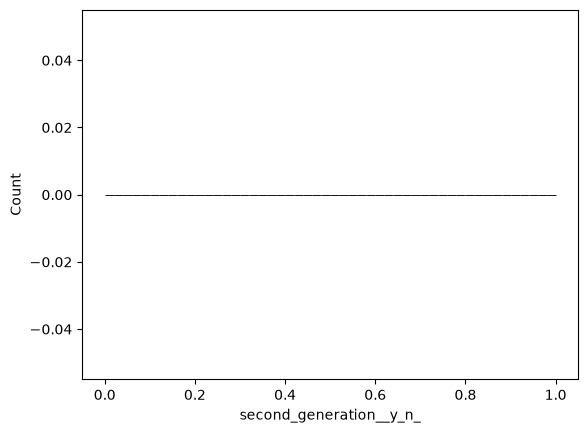

In [236]:
sns.histplot(df['second_generation__y_n_'], bins=50)

In [34]:
# CONVERT TO LOG VALUES TO REDUCE LONG TAIL 
second_generation_y_n = np.log1p(df['second_generation__y_n_'])
sns.histplot(price_logs, bins=50)

TypeError: loop of ufunc does not support argument 0 of type str which has no callable log1p method

## METADATA - DATA DICTIONARY

cn              Control number for most recent tree measurement
prev_tre_cn1    Control number for the previous tree measurement
spcd1           Species ID code of most recent measurement
prev_tre_cn2    Species ID code for a previous tree measurement
spcd2           3600439
prev_tre_cn3     956846
spcd3           1709900
prev_tre_cn4     288741
spcd4            951837
prev_tre_cn5      23288
spcd5            288668
prev_tre_cn6          0
spcd6             23288
dif1            Difference in tree measurement between current measure and 1st previous measure
dif2            Difference in tree measurement between 1st previous measure and 2nd previous measure
dif3             Difference in tree measurement between 2nd previous measure and 3rd previous measure
dif4             Difference in tree measurement between 3rd previous measure and 4th previous measure
dif5             Difference in tree measurement between 4th previous measure and 5th previous measure
difs             118013
spcd_t1         3600439



In [ ]:
# for col in df.columns:
#    print(col)

In [146]:
# SHOW FREQUENCY OF ALL UNIQUE VALUES PRESENT IN CATEGORICAL COLUMNS
for c in categorical_columns:
    print(df[c].value_counts())

df[categorical_columns] = df[categorical_columns].apply(lambda col: col.str.strip())


lifeform
<bound method StringMethods.lower of <pandas.core.strings.accessor.StringMethods object at 0x0000016ED9C65690>>    1182
Name: count, dtype: int64
state
<bound method StringMethods.lower of <pandas.core.strings.accessor.StringMethods object at 0x0000016EDC2AA550>>    1182
Name: count, dtype: int64
conservation_status__epbc_
<bound method StringMethods.lower of <pandas.core.strings.accessor.StringMethods object at 0x0000016EDC1E3A50>>    1182
Name: count, dtype: int64
broad_habitat_group
<bound method StringMethods.lower of <pandas.core.strings.accessor.StringMethods object at 0x0000016EDC16AD90>>    1182
Name: count, dtype: int64
research_to_support_translocation_
<bound method StringMethods.lower of <pandas.core.strings.accessor.StringMethods object at 0x0000016EDC2EBF10>>    1182
Name: count, dtype: int64
mitigation_translocation?
<bound method StringMethods.lower of <pandas.core.strings.accessor.StringMethods object at 0x0000016EDC09AA50>>    1182
Name: count, dtype: int64
h

In [128]:
numerical_columns   = (
    df.select_dtypes(include=["number"])
      .count()
      .loc[lambda counts: counts >= 700]
      .index
      .tolist()
)
numerical_columns

['translocation_number',
 'treatment_number',
 'presite_preparation__all_',
 'grazing_protection__all_',
 'watering__all_']

In [129]:
# EDA WITH PANDAS
         
# DESCRIBE STATISTICAL ATTRIBUTES OF EACH NUMERICAL COLUMN
for n in numerical_columns:
    print(df[n].describe)

# COPY OUTPUT OF THESE TWO EDA LOOPS AND POST TO CHAT-GPT WITH THE PROMPT
#    Create a pydantic data validation class for this request

<bound method NDFrame.describe of 0        10
1        11
2       854
3       854
4       855
       ... 
1177    257
1178    258
1179    259
1180    260
1181    261
Name: translocation_number, Length: 1182, dtype: int64>
<bound method NDFrame.describe of 0       1.0
1       1.0
2       1.0
3       2.0
4       1.0
       ... 
1177    1.0
1178    1.0
1179    1.0
1180    1.0
1181    1.0
Name: treatment_number, Length: 1182, dtype: float64>
<bound method NDFrame.describe of 0       NaN
1       NaN
2       NaN
3       NaN
4       NaN
       ... 
1177    0.0
1178    1.0
1179    NaN
1180    NaN
1181    NaN
Name: presite_preparation__all_, Length: 1182, dtype: float64>
<bound method NDFrame.describe of 0       NaN
1       NaN
2       NaN
3       NaN
4       NaN
       ... 
1177    1.0
1178    0.0
1179    NaN
1180    NaN
1181    NaN
Name: grazing_protection__all_, Length: 1182, dtype: float64>
<bound method NDFrame.describe of 0       1.0
1       1.0
2       NaN
3       NaN
4       NaN
       